In [184]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

def shift_signal(signal, shift):
    if shift > 0:
        # Add zeros at the end
        padded = np.pad(signal, (0, shift), 'constant')
        return padded[:-shift]
    elif shift < 0:
        # Add zeros at the beginning
        padded = np.pad(signal, (-shift, 0), 'constant')
        return padded[-shift:]
    else:
        return signal

In [189]:
corr_matrix = np.load("data/coherence/corr_matrix_20230709_102350_SHRU920_VLA2_ch0.npy")
lag_matrix = np.load("data/coherence/lag_matrix_20230709_102350_SHRU920_VLA2_ch0.npy")
time_matrix = np.load("data/coherence/time_matrix_20230709_102350_SHRU920_VLA2_ch0.npy")
sig_matrix = np.load("data/coherence/sig_matrix_20230709_102350_SHRU920_VLA2_ch0.npy")

In [194]:
corr_matrix

array([[1.99056141, 1.43941786, 1.37234536, ..., 1.29380737, 1.35080627,
        1.3424044 ],
       [1.59407757, 1.34102354, 1.34299933, ..., 1.107971  , 1.10414904,
        1.09102614],
       [1.51165922, 1.41219239, 1.34740696, ..., 1.10947588, 1.0809186 ,
        1.0862679 ],
       ...,
       [1.29733596, 1.25146115, 1.18152561, ..., 1.16821282, 1.15273801,
        1.1120188 ],
       [1.32103709, 1.24175297, 1.18447528, ..., 1.18292507, 1.13623731,
        1.11175775],
       [1.27870074, 1.21640906, 1.14797683, ..., 1.15989709, 1.12955354,
        1.13008768]])

## Coherence of each pulse with subsequent pulses

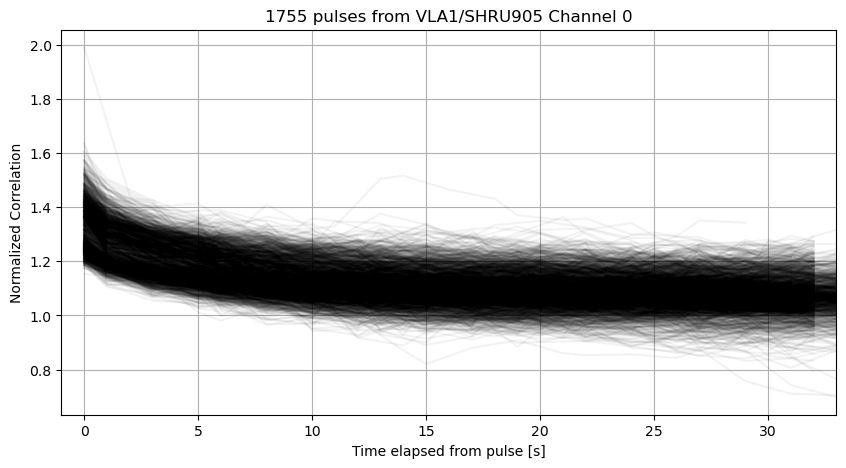

In [191]:
fig = plt.figure(figsize=(10, 5))
ax = plt.gca()
[ax.plot(time_matrix[i], corr_matrix[i], "k-", alpha=0.05, zorder=10) for i in range(corr_matrix.shape[0])]
ax.set_xlim(-1, 33)
# ax.set_ylim(0.6, 1.01)
ax.set_xlabel("Time elapsed from pulse [s]")
ax.set_ylabel("Normalized Correlation")
ax.grid(True)
ax.set_title(f"{corr_matrix.shape[0]} pulses from VLA1/SHRU905 Channel 0")
plt.show()

# Stacked pulses

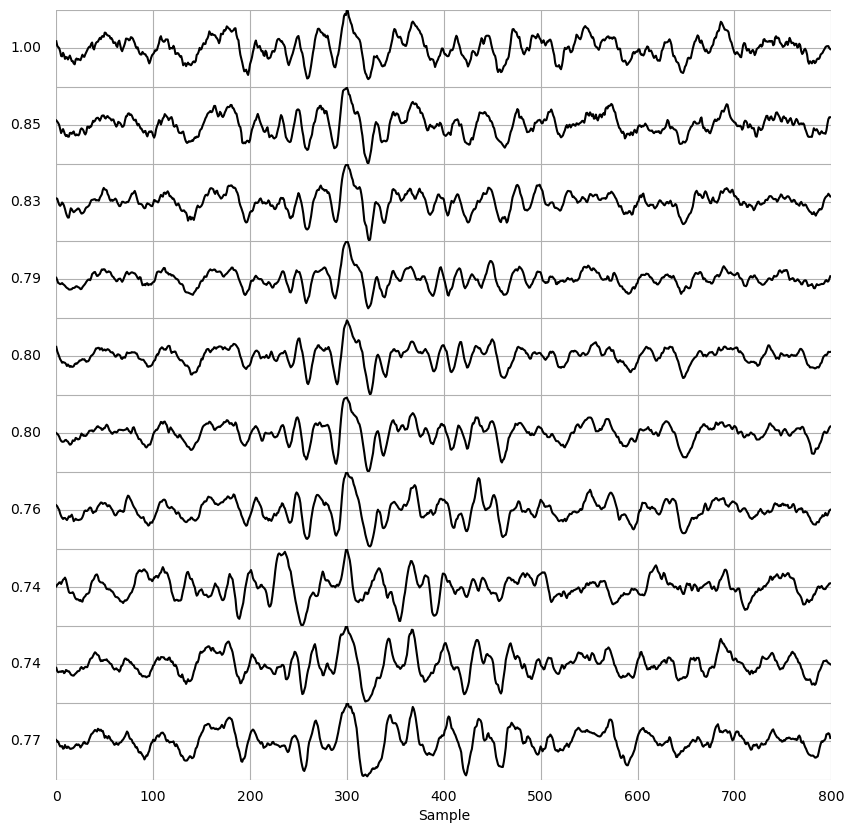

In [160]:
fig, axs = plt.subplots(nrows=10, ncols=1, figsize=(10, 10), gridspec_kw={"hspace": 0.0})

# Shift the signals
shifted = [shift_signal(sig_matrix[i], int(lag_matrix[0, i])) for i in range(10)]
summed = np.array(shifted).sum(axis=0)

for i, ax in enumerate(axs):
    sig = shifted[i][700:1500]
    ax.plot(sig / max(abs(sig)), "k")
    
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", which="both", bottom=False, top=False)
    ax.tick_params(axis="y", which="both", left=False, right=False)
    ax.set_yticklabels([])
    ax.grid(True)
    ax.set_xlim(0, 800)
    ax.set_ylim(-1, 1)
    ax.set_ylabel(f"{corr_matrix[0, i]:.2f}", rotation=0, ha="right", va="center")
    if i == len(axs) - 1:
        ax.set_xlabel("Sample")
    else:
        ax.set_xticklabels([])
    
plt.show()

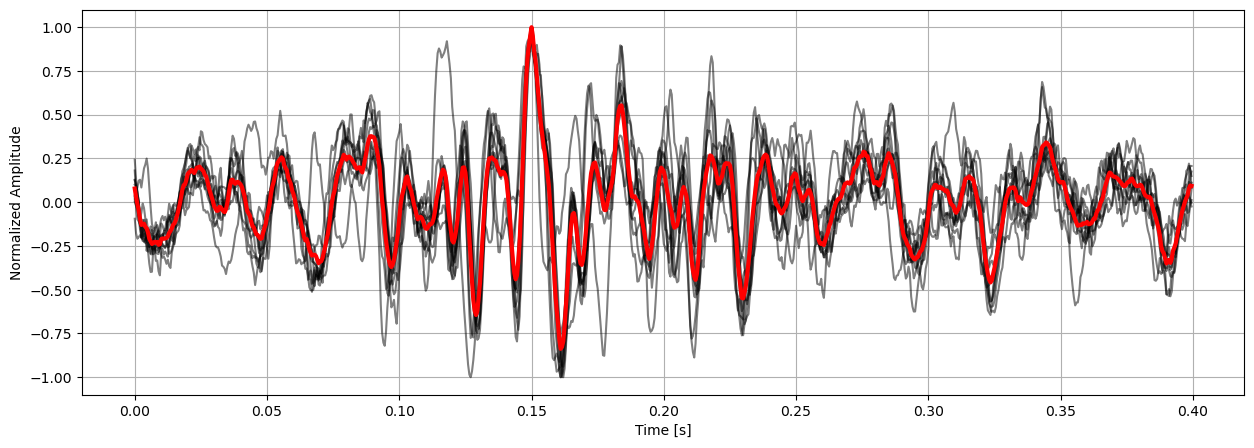

In [183]:
fig = plt.figure(figsize=(15, 5))
ax = plt.gca()

summed = np.array(shifted).sum(axis=0)
tvec = np.arange(0, 800) / 2000
[ax.plot(tvec, shifted[i][700:1500] / max(abs(shifted[i][700:1500])), "k", alpha=0.5) for i in range(10)]
ax.plot(tvec, summed[700:1500] / max(abs(summed[700:1500])), "r", linewidth=3, zorder=50)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Normalized Amplitude")
ax.grid(True)
fig.savefig()


In [ ]:
# TODO: Coherently sum signals that are NOT downsampled and then plot the spectrogram

from scipy import signal

f, t, Sxx = signal.spectrogram(
        summed, fs, nperseg=nperseg, nfft=nfft, noverlap=int(overlap * nperseg)
    )